In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

df_raw = pd.read_csv('train.csv')
print(f"Dataset Shape: {df_raw.shape}")
print(df_raw.info())

Dataset Shape: (9800, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-nu

In [2]:
df_cleaned = df_raw.copy()

df_cleaned['Postal Code'] = df_cleaned['Postal Code'].fillna(5401.0).astype(int)

df_cleaned['Order Date'] = pd.to_datetime(df_cleaned['Order Date'], format='%d/%m/%Y')
df_cleaned['Ship Date'] = pd.to_datetime(df_cleaned['Ship Date'], format='%d/%m/%Y')

df_cleaned['Shipping Days'] = (df_cleaned['Ship Date'] - df_cleaned['Order Date']).dt.days

for col in ['Customer Name', 'City', 'State', 'Product Name']:
    df_cleaned[col] = df_cleaned[col].str.strip()

print(f"Missing values remaining: {df_cleaned.isnull().sum().sum()}")
display(df_cleaned.head())

Missing values remaining: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Shipping Days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,7


In [3]:
dates = pd.concat([df_cleaned['Order Date'], df_cleaned['Ship Date']]).drop_duplicates().sort_values()
dim_date = pd.DataFrame({'FullDate': dates})
dim_date['DateKey'] = dim_date['FullDate'].dt.strftime('%Y%m%d').astype(int)
dim_date['Year'] = dim_date['FullDate'].dt.year
dim_date['Quarter'] = dim_date['FullDate'].dt.quarter
dim_date['Month'] = dim_date['FullDate'].dt.month
dim_date['MonthName'] = dim_date['FullDate'].dt.strftime('%B')
dim_date['DayOfWeek'] = dim_date['FullDate'].dt.day_name()
dim_date = dim_date[['DateKey', 'FullDate', 'Year', 'Quarter', 'Month', 'MonthName', 'DayOfWeek']]

dim_customer = df_cleaned[['Customer ID', 'Customer Name', 'Segment']].drop_duplicates(subset=['Customer ID']).reset_index(drop=True)
dim_customer.columns = ['CustomerID', 'CustomerName', 'Segment']

dim_location = df_cleaned[['Country', 'City', 'State', 'Region', 'Postal Code']].drop_duplicates().reset_index(drop=True)
dim_location.reset_index(inplace=True)
dim_location.rename(columns={'index': 'LocationKey', 'Postal Code': 'PostalCode'}, inplace=True)
dim_location['LocationKey'] = dim_location['LocationKey'] + 1

dim_product = df_cleaned[['Product ID', 'Category', 'Sub-Category', 'Product Name']].drop_duplicates(subset=['Product ID']).reset_index(drop=True)
dim_product.columns = ['ProductID', 'Category', 'SubCategory', 'ProductName']

fact_sales = df_cleaned.copy()
fact_sales['OrderDateKey'] = fact_sales['Order Date'].dt.strftime('%Y%m%d').astype(int)
fact_sales['ShipDateKey'] = fact_sales['Ship Date'].dt.strftime('%Y%m%d').astype(int)
fact_sales = fact_sales.merge(
    dim_location, 
    left_on=['Country', 'City', 'State', 'Region', 'Postal Code'], 
    right_on=['Country', 'City', 'State', 'Region', 'PostalCode']
)

fact_sales = fact_sales[[
    'Row ID', 'Order ID', 'OrderDateKey', 'ShipDateKey', 
    'Customer ID', 'LocationKey', 'Product ID', 'Ship Mode', 
    'Shipping Days', 'Sales'
]]
fact_sales.columns = [
    'FactSalesID', 'OrderID', 'OrderDateKey', 'ShipDateKey', 
    'CustomerID', 'LocationKey', 'ProductID', 'ShipMode', 
    'ShippingDays', 'SalesAmount'
]

def render_dw_table(df, title, entity_type, primary_key, total_rows):
    styled = (
        df.head(3).style
        .set_table_styles([
            {'selector': 'th.col_heading', 'props': [('background-color', '#114F6A' if entity_type == 'FACT' else '#1FA4B1'), ('color', '#FFFFFF'), ('font-weight', '600'), ('text-align', 'center'), ('padding', '6px 10px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
            {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 10px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
            {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#F8FAFC')]}
        ])
        .hide(axis='index')
    )
    badge_bg = '#114F6A' if entity_type == 'FACT' else '#0284C7'
    header_html = f"""
    <div style="margin-top: 18px; margin-bottom: 6px; font-family: 'DejaVu Sans', sans-serif;">
        <span style="background: {badge_bg}; color: white; padding: 2px 8px; border-radius: 4px; font-size: 10px; font-weight: bold; margin-right: 8px;">{entity_type}</span>
        <strong style="font-size: 13px; color: #0F172A;">{title}</strong>
        <span style="font-size: 11px; color: #64748B; margin-left: 8px;">(PK: <code>{primary_key}</code> | Total: <b>{total_rows:,}</b> records)</span>
    </div>
    """
    display(HTML(header_html))
    display(styled)

fact_display = fact_sales.copy()
fact_display['SalesAmount'] = fact_display['SalesAmount'].apply(lambda x: f"${x:,.2f}")

render_dw_table(dim_product, "DIM_PRODUCT (Katalog Produk)", "DIMENSION", "ProductID", len(dim_product))
render_dw_table(dim_customer, "DIM_CUSTOMER (Entitas Pelanggan)", "DIMENSION", "CustomerID", len(dim_customer))
render_dw_table(dim_location, "DIM_LOCATION (Hirarki Wilayah & Lokasi)", "DIMENSION", "LocationKey", len(dim_location))
render_dw_table(dim_date, "DIM_DATE (Atribut Temporal)", "DIMENSION", "DateKey", len(dim_date))
render_dw_table(fact_display, "FACT_SALES (Tabel Fakta Transaksi Penjualan)", "FACT", "FactSalesID", len(fact_sales))

ProductID,Category,SubCategory,ProductName
FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase
FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back"
OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal


CustomerID,CustomerName,Segment
CG-12520,Claire Gute,Consumer
DV-13045,Darrin Van Huff,Corporate
SO-20335,Sean O'Donnell,Consumer


LocationKey,Country,City,State,Region,PostalCode
1,United States,Henderson,Kentucky,South,42420
2,United States,Los Angeles,California,West,90036
3,United States,Fort Lauderdale,Florida,South,33311


DateKey,FullDate,Year,Quarter,Month,MonthName,DayOfWeek
20150103,2015-01-03 00:00:00,2015,1,1,January,Saturday
20150104,2015-01-04 00:00:00,2015,1,1,January,Sunday
20150105,2015-01-05 00:00:00,2015,1,1,January,Monday


FactSalesID,OrderID,OrderDateKey,ShipDateKey,CustomerID,LocationKey,ProductID,ShipMode,ShippingDays,SalesAmount
1,CA-2017-152156,20171108,20171111,CG-12520,1,FUR-BO-10001798,Second Class,3,$261.96
2,CA-2017-152156,20171108,20171111,CG-12520,1,FUR-CH-10000454,Second Class,3,$731.94
3,CA-2017-138688,20170612,20170616,DV-13045,2,OFF-LA-10000240,Second Class,4,$14.62


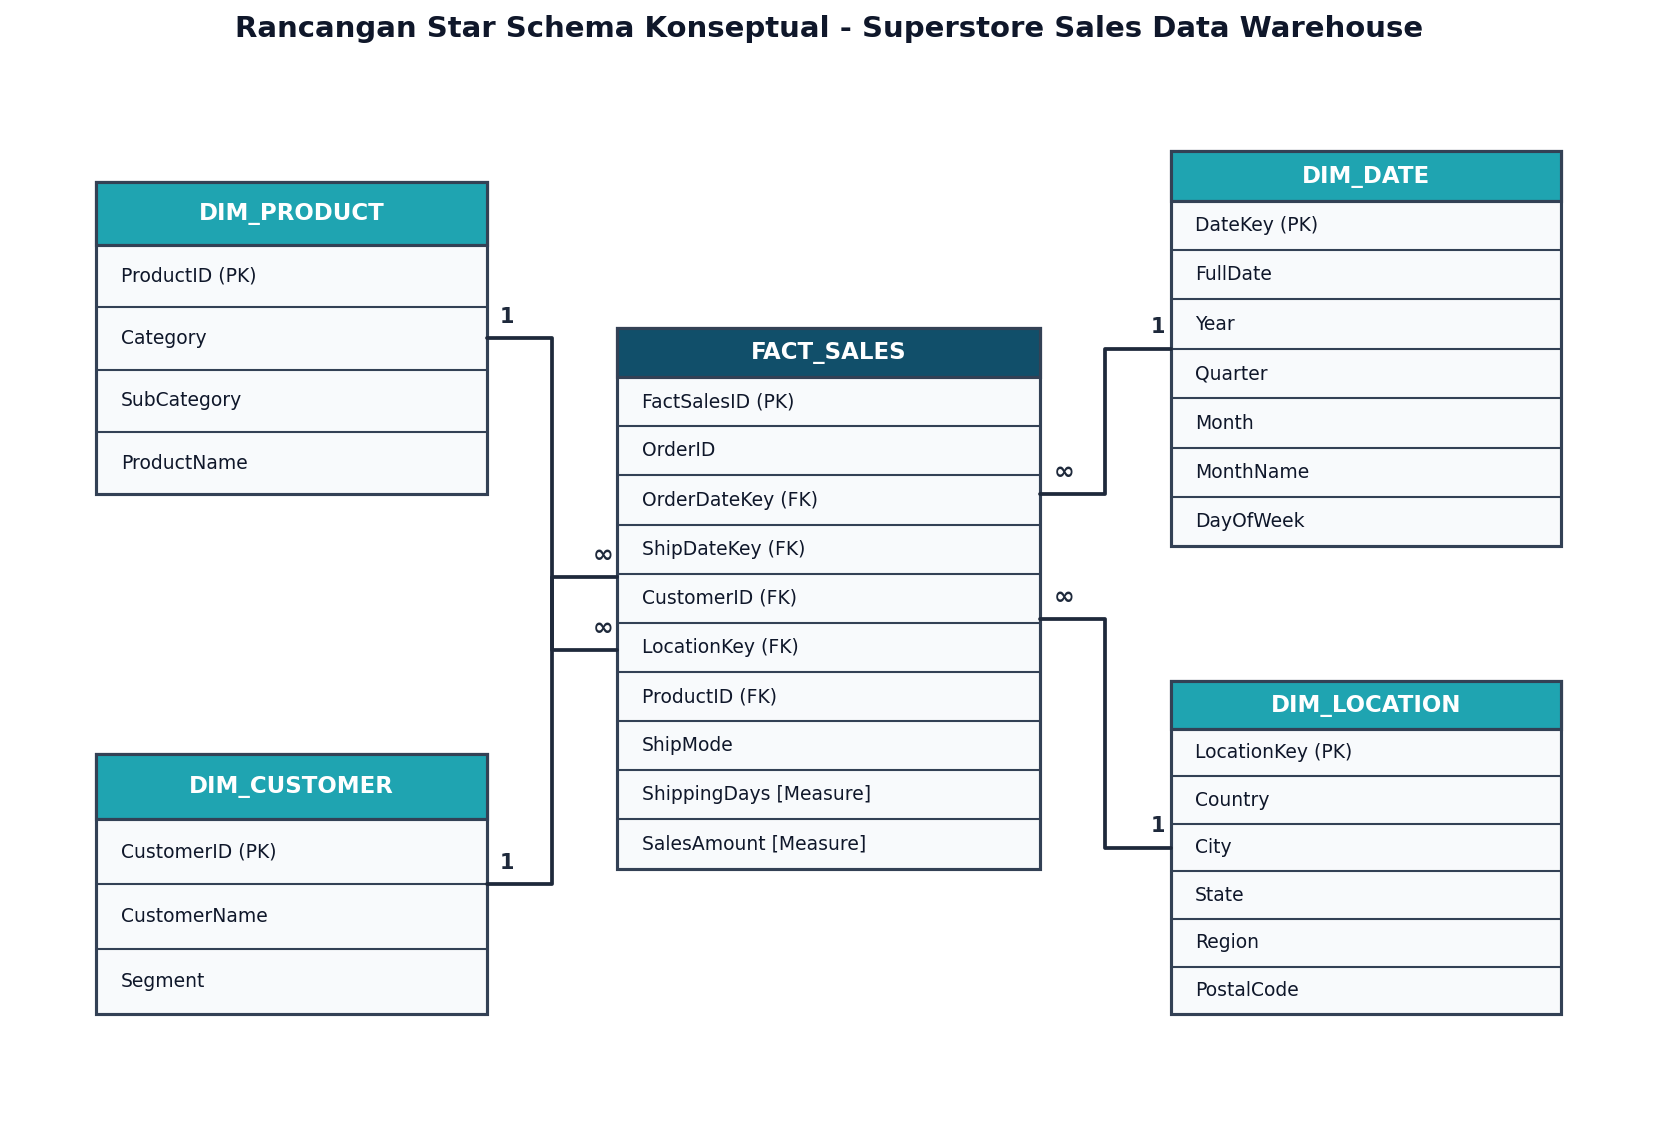

In [4]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 9), dpi=150)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

hdr_fact = '#114F6A'
hdr_dim = '#1FA4B1'
bg_card = '#F8FAFC'
border_col = '#334155'
text_hdr = '#FFFFFF'
text_body = '#0F172A'

def draw_table(ax, x, y, w, h, title, fields, hdr_color):
    n = len(fields) + 1
    row_h = h / n
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="square,pad=0", linewidth=1.5, edgecolor=border_col, facecolor=bg_card)
    ax.add_patch(rect)
    hdr = patches.Rectangle((x, y + h - row_h), w, row_h, linewidth=1.5, edgecolor=border_col, facecolor=hdr_color)
    ax.add_patch(hdr)
    ax.text(x + w/2, y + h - row_h/2, title, ha='center', va='center', fontsize=11, fontweight='bold', color=text_hdr)
    for i, f in enumerate(fields):
        cur_y = y + h - (i + 2) * row_h
        ax.plot([x, x + w], [cur_y + row_h, cur_y + row_h], color=border_col, lw=1)
        ax.text(x + 1.5, cur_y + row_h/2, f, ha='left', va='center', fontsize=9, color=text_body)

draw_table(ax, 37, 24, 26, 52, "FACT_SALES", [
    "FactSalesID (PK)",
    "OrderID",
    "OrderDateKey (FK)",
    "ShipDateKey (FK)",
    "CustomerID (FK)",
    "LocationKey (FK)",
    "ProductID (FK)",
    "ShipMode",
    "ShippingDays [Measure]",
    "SalesAmount [Measure]"
], hdr_fact)

draw_table(ax, 5, 60, 24, 30, "DIM_PRODUCT", [
    "ProductID (PK)",
    "Category",
    "SubCategory",
    "ProductName"
], hdr_dim)

draw_table(ax, 5, 10, 24, 25, "DIM_CUSTOMER", [
    "CustomerID (PK)",
    "CustomerName",
    "Segment"
], hdr_dim)

draw_table(ax, 71, 55, 24, 38, "DIM_DATE", [
    "DateKey (PK)",
    "FullDate",
    "Year",
    "Quarter",
    "Month",
    "MonthName",
    "DayOfWeek"
], hdr_dim)

draw_table(ax, 71, 10, 24, 32, "DIM_LOCATION", [
    "LocationKey (PK)",
    "Country",
    "City",
    "State",
    "Region",
    "PostalCode"
], hdr_dim)

ax.plot([29, 33, 33, 37], [75, 75, 45, 45], color='#1E293B', lw=1.8)
ax.text(29.8, 76.5, "1", fontsize=10, fontweight='bold', color='#1E293B')
ax.text(35.5, 46.5, "∞", fontsize=12, fontweight='bold', color='#1E293B')

ax.plot([29, 33, 33, 37], [22.5, 22.5, 52, 52], color='#1E293B', lw=1.8)
ax.text(29.8, 24, "1", fontsize=10, fontweight='bold', color='#1E293B')
ax.text(35.5, 53.5, "∞", fontsize=12, fontweight='bold', color='#1E293B')

ax.plot([71, 67, 67, 63], [74, 74, 60, 60], color='#1E293B', lw=1.8)
ax.text(69.8, 75.5, "1", fontsize=10, fontweight='bold', color='#1E293B')
ax.text(63.8, 61.5, "∞", fontsize=12, fontweight='bold', color='#1E293B')

ax.plot([71, 67, 67, 63], [26, 26, 48, 48], color='#1E293B', lw=1.8)
ax.text(69.8, 27.5, "1", fontsize=10, fontweight='bold', color='#1E293B')
ax.text(63.8, 49.5, "∞", fontsize=12, fontweight='bold', color='#1E293B')

plt.title("Rancangan Star Schema Konseptual - Superstore Sales Data Warehouse", fontsize=14, fontweight='bold', pad=20, color='#0F172A')
plt.savefig("star_schema_diagram.png", bbox_inches='tight')
plt.show()

In [5]:
conn = sqlite3.connect('superstore_dw.db')
cursor = conn.cursor()

dim_date.to_sql('Dim_Date', conn, if_exists='replace', index=False)
dim_customer.to_sql('Dim_Customer', conn, if_exists='replace', index=False)
dim_location.to_sql('Dim_Location', conn, if_exists='replace', index=False)
dim_product.to_sql('Dim_Product', conn, if_exists='replace', index=False)
fact_sales.to_sql('Fact_Sales', conn, if_exists='replace', index=False)

tables = cursor.execute("SELECT name FROM sqlite_master WHERE type='table';").fetchall()
print(f"Tables successfully loaded to DW: {[t[0] for t in tables]}")

schema_query = """
SELECT 
    f.OrderID,
    d.FullDate AS OrderDate,
    d.Quarter,
    d.Year,
    c.CustomerName,
    c.Segment,
    l.Region,
    l.State,
    p.Category,
    p.SubCategory,
    f.ShipMode,
    f.ShippingDays,
    f.SalesAmount
FROM Fact_Sales f
JOIN Dim_Date d ON f.OrderDateKey = d.DateKey
JOIN Dim_Customer c ON f.CustomerID = c.CustomerID
JOIN Dim_Location l ON f.LocationKey = l.LocationKey
JOIN Dim_Product p ON f.ProductID = p.ProductID
LIMIT 5;
"""

df_dw_relational = pd.read_sql_query(schema_query, conn)
conn.close()

styled_join = (
    df_dw_relational.style
    .set_caption("Tabel 2.1: Uji Relasi Multi-Dimensi Data Warehouse (Star Schema Join)")
    .format({'SalesAmount': '${:,.2f}'})
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '13px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding-bottom', '8px'), ('color', '#114F6A')]},
        {'selector': 'th.col_heading', 'props': [('background-color', '#114F6A'), ('color', '#FFFFFF'), ('font-weight', '600'), ('text-align', 'center'), ('padding', '6px 10px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px 10px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#F8FAFC')]}
    ])
    .hide(axis='index')
)
display(styled_join)

Tables successfully loaded to DW: ['Dim_Date', 'Dim_Customer', 'Dim_Location', 'Dim_Product', 'Fact_Sales']


OrderID,OrderDate,Quarter,Year,CustomerName,Segment,Region,State,Category,SubCategory,ShipMode,ShippingDays,SalesAmount
CA-2017-152156,2017-11-08 00:00:00,4,2017,Claire Gute,Consumer,South,Kentucky,Furniture,Bookcases,Second Class,3,$261.96
CA-2017-152156,2017-11-08 00:00:00,4,2017,Claire Gute,Consumer,South,Kentucky,Furniture,Chairs,Second Class,3,$731.94
CA-2017-138688,2017-06-12 00:00:00,2,2017,Darrin Van Huff,Corporate,West,California,Office Supplies,Labels,Second Class,4,$14.62
US-2016-108966,2016-10-11 00:00:00,4,2016,Sean O'Donnell,Consumer,South,Florida,Furniture,Tables,Standard Class,7,$957.58
US-2016-108966,2016-10-11 00:00:00,4,2016,Sean O'Donnell,Consumer,South,Florida,Office Supplies,Storage,Standard Class,7,$22.37


In [6]:
metrics = []
variables = [
    ('Sales (USD)', df_cleaned['Sales']),
    ('Shipping Duration (Days)', df_cleaned['Shipping Days'])
]

for label, series in variables:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    metrics.append({
        'Metric Variable': label,
        'Observations (N)': f"{int(series.count()):,}",
        'Mean': f"{series.mean():,.2f}",
        'Std Dev': f"{series.std():,.2f}",
        'Min': f"{series.min():,.2f}",
        'Q1 (25%)': f"{q1:,.2f}",
        'Median (50%)': f"{series.median():,.2f}",
        'Q3 (75%)': f"{q3:,.2f}",
        'Max': f"{series.max():,.2f}",
        'IQR': f"{iqr:,.2f}",
        'Skewness': f"{series.skew():+.2f}",
        'Kurtosis': f"{series.kurt():+.2f}"
    })

df_desc_summary = pd.DataFrame(metrics).set_index('Metric Variable')

styled_table = (
    df_desc_summary.style
    .set_caption("Tabel 4.1: Ringkasan Statistik Deskriptif Variabel Kuantitatif Superstore")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '13px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding-bottom', '8px'), ('color', '#114F6A')]},
        {'selector': 'th.col_heading', 'props': [('background-color', '#114F6A'), ('color', '#FFFFFF'), ('font-weight', '600'), ('text-align', 'center'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'th.row_heading', 'props': [('background-color', '#F1F5F9'), ('color', '#0F172A'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#F8FAFC')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#E2E8F0')]}
    ])
)
display(styled_table)

,Observations (N),Mean,Std Dev,Min,Q1 (25%),Median (50%),Q3 (75%),Max,IQR,Skewness,Kurtosis
Metric Variable,,,,,,,,,,,
Sales (USD),"9,800",230.77,626.65,0.44,17.25,54.49,210.61,"22,638.48",193.36,+12.98,+304.45
Shipping Duration (Days),"9,800",3.96,1.75,0.00,3.00,4.00,5.00,7.00,2.00,-0.43,-0.28


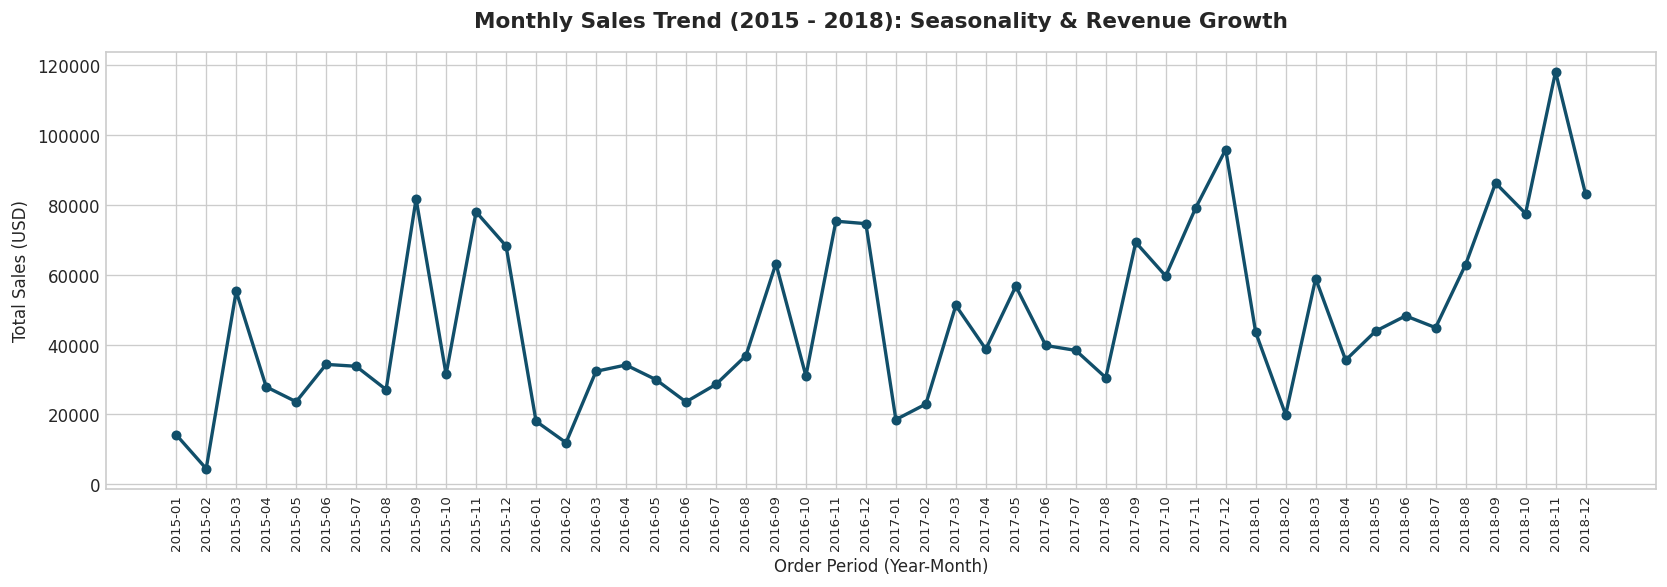

In [7]:
df_cleaned['YearMonth'] = df_cleaned['Order Date'].dt.to_period('M')
monthly_sales = df_cleaned.groupby('YearMonth')['Sales'].sum().reset_index()
monthly_sales['YearMonth_Str'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales['YearMonth_Str'], monthly_sales['Sales'], marker='o', color='#114F6A', linewidth=2, markersize=5)
plt.title('Monthly Sales Trend (2015 - 2018): Seasonality & Revenue Growth', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Order Period (Year-Month)', fontsize=10)
plt.ylabel('Total Sales (USD)', fontsize=10)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

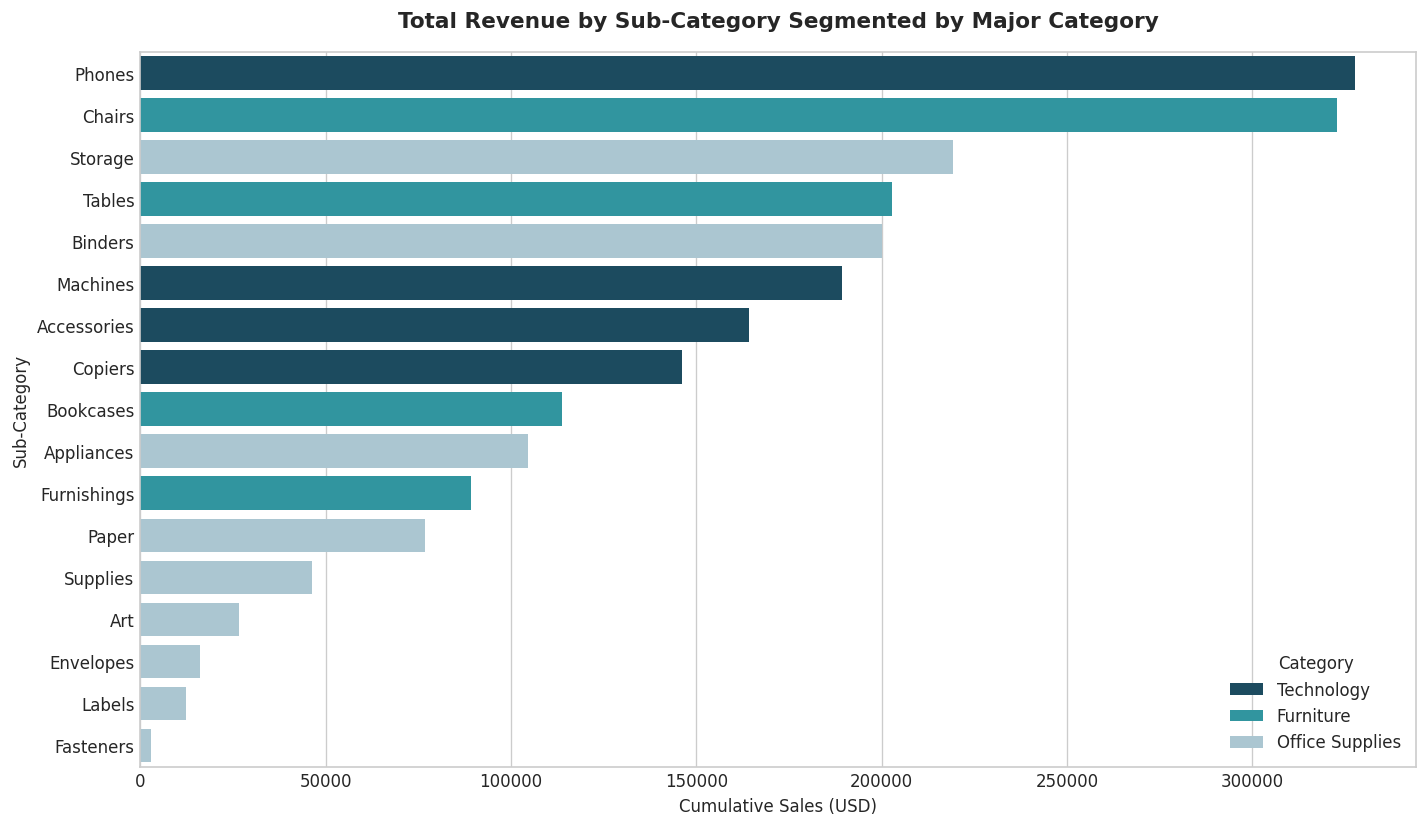

In [8]:
subcat_perf = df_cleaned.groupby(['Category', 'Sub-Category'])['Sales'].sum().reset_index()
subcat_perf = subcat_perf.sort_values('Sales', ascending=False)

plt.figure(figsize=(12, 7))
palette_map = {'Technology': '#114F6A', 'Furniture': '#1FA4B1', 'Office Supplies': '#A5C9D7'}
sns.barplot(
    data=subcat_perf, 
    y='Sub-Category', 
    x='Sales', 
    hue='Category', 
    dodge=False, 
    palette=palette_map
)
plt.title('Total Revenue by Sub-Category Segmented by Major Category', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Cumulative Sales (USD)', fontsize=10)
plt.ylabel('Sub-Category', fontsize=10)
plt.legend(title='Category', loc='lower right')
plt.tight_layout()
plt.show()

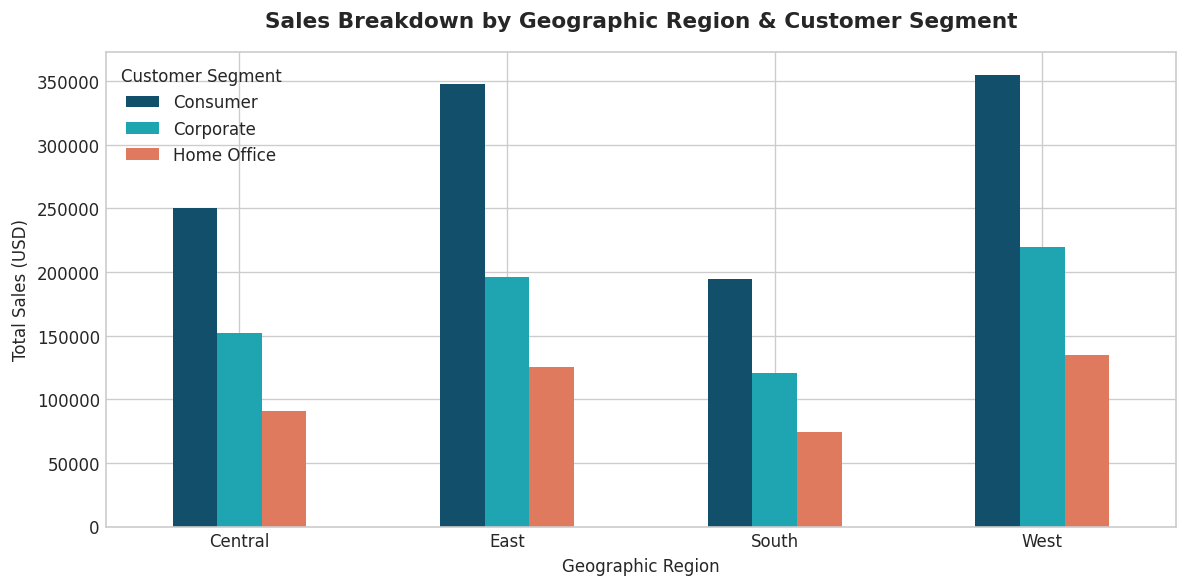

In [9]:
pivot_region_segment = df_cleaned.pivot_table(
    index='Region', 
    columns='Segment', 
    values='Sales', 
    aggfunc='sum'
)

fig, ax = plt.subplots(figsize=(10, 5))
pivot_region_segment.plot(kind='bar', stacked=False, ax=ax, color=['#114F6A', '#1FA4B1', '#E07A5F'])
plt.title('Sales Breakdown by Geographic Region & Customer Segment', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Geographic Region', fontsize=10)
plt.ylabel('Total Sales (USD)', fontsize=10)
plt.xticks(rotation=0)
plt.legend(title='Customer Segment')
plt.tight_layout()
plt.show()

In [10]:
total_revenue = df_cleaned['Sales'].sum()

yearly_df = df_cleaned.groupby(df_cleaned['Order Date'].dt.year)['Sales'].agg(['sum', 'count']).reset_index()
yearly_df.columns = ['Tahun', 'Total Sales (USD)', 'Volume Order']
yearly_df['YoY Growth (%)'] = yearly_df['Total Sales (USD)'].pct_change() * 100
yearly_df['Pangsa Revenue (%)'] = (yearly_df['Total Sales (USD)'] / total_revenue) * 100

top2_subcats_sales = subcat_perf.head(2)['Sales'].sum()
top2_subcats_share = (top2_subcats_sales / total_revenue) * 100
yoy_2018 = yearly_df.loc[yearly_df['Tahun'] == 2018, 'YoY Growth (%)'].values[0]

region_df = df_cleaned.groupby('Region')['Sales'].agg(['sum', 'count']).reset_index()
region_df.columns = ['Wilayah (Region)', 'Total Sales (USD)', 'Volume Order']
region_df['Pangsa Wilayah (%)'] = (region_df['Total Sales (USD)'] / total_revenue) * 100
region_df['Avg Order Value (USD)'] = region_df['Total Sales (USD)'] / region_df['Volume Order']
region_df = region_df.sort_values('Total Sales (USD)', ascending=False).reset_index(drop=True)

kpi_html = f"""
<div style="display: flex; gap: 16px; margin-bottom: 20px; font-family: 'DejaVu Sans', sans-serif;">
    <div style="flex: 1; background: #F8FAFC; border: 1px solid #CBD5E1; border-top: 4px solid #114F6A; border-radius: 6px; padding: 14px 18px;">
        <span style="font-size: 11px; font-weight: bold; color: #64748B; text-transform: uppercase; letter-spacing: 0.5px;">Total Kumulatif Revenue</span>
        <div style="font-size: 20px; font-weight: bold; color: #114F6A; margin-top: 6px;">${total_revenue:,.2f}</div>
        <span style="font-size: 11px; color: #059669; font-weight: 600;">9,800 Total Transaksi</span>
    </div>
    <div style="flex: 1; background: #F8FAFC; border: 1px solid #CBD5E1; border-top: 4px solid #1FA4B1; border-radius: 6px; padding: 14px 18px;">
        <span style="font-size: 11px; font-weight: bold; color: #64748B; text-transform: uppercase; letter-spacing: 0.5px;">Top 2 Sub-Kategori Share</span>
        <div style="font-size: 20px; font-weight: bold; color: #1FA4B1; margin-top: 6px;">{top2_subcats_share:.2f}%</div>
        <span style="font-size: 11px; color: #475569;">Phones & Chairs (${top2_subcats_sales:,.2f})</span>
    </div>
    <div style="flex: 1; background: #F8FAFC; border: 1px solid #CBD5E1; border-top: 4px solid #0284C7; border-radius: 6px; padding: 14px 18px;">
        <span style="font-size: 11px; font-weight: bold; color: #64748B; text-transform: uppercase; letter-spacing: 0.5px;">YoY Growth 2018</span>
        <div style="font-size: 20px; font-weight: bold; color: #0284C7; margin-top: 6px;">+{yoy_2018:.2f}%</div>
        <span style="font-size: 11px; color: #059669; font-weight: 600;">Akselerasi 3,258 Orders</span>
    </div>
    <div style="flex: 1; background: #F8FAFC; border: 1px solid #CBD5E1; border-top: 4px solid #E07A5F; border-radius: 6px; padding: 14px 18px;">
        <span style="font-size: 11px; font-weight: bold; color: #64748B; text-transform: uppercase; letter-spacing: 0.5px;">Pangsa Wilayah South</span>
        <div style="font-size: 20px; font-weight: bold; color: #E07A5F; margin-top: 6px;">17.21%</div>
        <span style="font-size: 11px; color: #DC2626; font-weight: 600;">Defisit (-14.19% vs West)</span>
    </div>
</div>
"""
display(HTML(kpi_html))

yearly_formatted = yearly_df.copy()
yearly_formatted['Total Sales (USD)'] = yearly_formatted['Total Sales (USD)'].apply(lambda x: f"${x:,.2f}")
yearly_formatted['Volume Order'] = yearly_formatted['Volume Order'].apply(lambda x: f"{x:,}")
yearly_formatted['YoY Growth (%)'] = yearly_formatted['YoY Growth (%)'].apply(lambda x: "-" if pd.isna(x) else f"{x:+.2f}%")
yearly_formatted['Pangsa Revenue (%)'] = yearly_formatted['Pangsa Revenue (%)'].apply(lambda x: f"{x:.2f}%")

styled_yearly = (
    yearly_formatted.style
    .set_caption("Tabel 5.1: Kinerja Penjualan Tahunan (Yearly Revenue Performance)")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '13px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding-bottom', '8px'), ('color', '#114F6A')]},
        {'selector': 'th.col_heading', 'props': [('background-color', '#114F6A'), ('color', '#FFFFFF'), ('font-weight', '600'), ('text-align', 'center'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#F8FAFC')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#E2E8F0')]}
    ])
    .hide(axis='index')
)
display(styled_yearly)

region_formatted = region_df.copy()
region_formatted['Total Sales (USD)'] = region_formatted['Total Sales (USD)'].apply(lambda x: f"${x:,.2f}")
region_formatted['Volume Order'] = region_formatted['Volume Order'].apply(lambda x: f"{x:,}")
region_formatted['Pangsa Wilayah (%)'] = region_formatted['Pangsa Wilayah (%)'].apply(lambda x: f"{x:.2f}%")
region_formatted['Avg Order Value (USD)'] = region_formatted['Avg Order Value (USD)'].apply(lambda x: f"${x:,.2f}")

styled_region = (
    region_formatted.style
    .set_caption("Tabel 5.2: Matriks Kontribusi Penjualan Antar Wilayah (Regional Performance Breakdown)")
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '13px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding-top', '16px'), ('padding-bottom', '8px'), ('color', '#114F6A')]},
        {'selector': 'th.col_heading', 'props': [('background-color', '#1FA4B1'), ('color', '#FFFFFF'), ('font-weight', '600'), ('text-align', 'center'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '8px 12px'), ('font-size', '11px'), ('border', '1px solid #CBD5E1')]},
        {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', '#F8FAFC')]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#E2E8F0')]}
    ])
    .hide(axis='index')
)
display(styled_region)

Tahun,Total Sales (USD),Volume Order,YoY Growth (%),Pangsa Revenue (%)
2015,"$479,856.21","1,953",-,21.22%
2016,"$459,436.01","2,055",-4.26%,20.32%
2017,"$600,192.55","2,534",+30.64%,26.54%
2018,"$722,052.02","3,258",+20.30%,31.93%


Wilayah (Region),Total Sales (USD),Volume Order,Pangsa Wilayah (%),Avg Order Value (USD)
West,"$710,219.68","3,140",31.40%,$226.18
East,"$669,518.73","2,785",29.60%,$240.40
Central,"$492,646.91","2,277",21.78%,$216.36
South,"$389,151.46","1,598",17.21%,$243.52
